# Phân tích Partition, Job, Stage và Task của Task 1

Notebook **thực thi Spark để đo**, không gán trước số partition hay Job/Stage ID. Mở bằng kernel Python của `.venv`, chọn **Restart Kernel → Run All**. Lưu notebook sau khi chạy để giữ các bảng đo.

## 1. Phạm vi và cách đối chiếu diagram

| Chế độ | Workflow được đo |
|---|---|
| `project` (mặc định) | Các hàm RDD thật trong `rdd_processing.py`: unpack → parse → filter HTTP 200 → enrich → reduceByKey → toDF → take(10) → CLI show |
| `diagram` | Mô hình bổ sung theo ảnh: classified rows → semantic counts / top countries / HTTP 200 count. Đây **không phải** workflow hiện có trong `execute_rdd_job()`. |

Các phép kiểm tra input/output partition chạy **sau** action nghiệp vụ, được gắn nhãn `audit.*`, nên không làm lệch ID của các job nghiệp vụ chạy trước. Notebook không ghi đè dữ liệu hoặc code project. Việc kiểm tra bổ sung có thể làm nóng filesystem cache, vì vậy đây không phải benchmark.

**Đơn vị:** dòng vật lý là dòng trong `raw_logs.txt`; entry là đoạn không rỗng sau tách `;`; output record là cặp key–count sau reduce. Số dòng không đồng nghĩa số request hoặc số bản ghi shuffle. Partition ID chỉ có ý nghĩa trong RDD/stage tương ứng. Một API action có thể tạo nhiều job; một task attempt là một lần thử xử lý partition.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, inspect
from contextlib import contextmanager
from urllib.request import build_opener, ProxyHandler
from urllib.parse import urlsplit, quote
import pandas as pd
from IPython.display import display, Markdown

MODE = "project"              # "project" hoặc "diagram"
CACHE_DIAGRAM = False          # Chỉ áp dụng cho MODE="diagram"
MASTER = "local[*]"            # Giống main() của project
assert MODE in {"project", "diagram"}
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "rdd_processing.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục spark-core-apis.")
INPUT = ROOT / "data/raw_logs.txt"
LOOKUP = ROOT / "data/ip_geolocation.csv"
assert INPUT.is_file() and LOOKUP.is_file(), "Thiếu file dữ liệu Task 1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import helper
import rdd_processing as pipeline
from pyspark import SparkContext, TaskContext, StorageLevel
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

def note(text): display(Markdown("**Nhận xét:** " + text))
def table(title, frame):
    display(Markdown("**" + title + "**"))
    with pd.option_context("display.max_rows", None, "display.max_colwidth", 120):
        display(frame)
def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""): h.update(chunk)
    return h.hexdigest()
manifest = pd.DataFrame([{"file": p.relative_to(ROOT).as_posix(), "bytes": p.stat().st_size,
                          "sha256": digest(p)}
                         for p in [INPUT, LOOKUP, ROOT/"rdd_processing.py", ROOT/"helper.py"]])
table("Nguồn của lần đo", manifest)
print("Python:", sys.executable, "| Mode:", MODE)
print("Code execute_rdd_job hiện tại:\n", inspect.getsource(pipeline.execute_rdd_job))

**Nguồn của lần đo**

,file,bytes,sha256
0,data/raw_logs.txt,119705574,e5935fea61abd4ab1900ca30ce8ea5c8267b8d185b5ba5d6f34d012cb4c65f38
1,data/ip_geolocation.csv,466,110b2327c8c17a1bd1edf063089ea0279abb334ffa32b2272b60499709e0a3dd
2,rdd_processing.py,9567,70eb5ad062e1441a9698968be8c693289985a30701bece0d2c78c9c2af939095
3,helper.py,3328,cac77a24e1ec2a4cb4d1165459ed0cde4223cd55df86efa12f27a74c7e32d9c0


Python: D:\spark-core-apis\.venv\Scripts\python.exe | Mode: project
Code execute_rdd_job hiện tại:
 def execute_rdd_job(sc, spark, input_path: str, ip_country_map: dict):
    broadcast_ip_map = sc.broadcast(ip_country_map)
    invalid_log_counter = sc.accumulator(0)

    t0 = time.perf_counter()

    # Transformation
    raw_rdd = sc.textFile(input_path)
    unpacked_rdd = unpack_compound_logs(raw_rdd)
    parsed_rdd   = parse_and_audit_logs(unpacked_rdd, invalid_log_counter)
    filtered_rdd = filter_successful_requests(parsed_rdd)
    enriched_rdd = enrich_with_country(filtered_rdd, broadcast_ip_map)
    rdd_counts  = aggregate_access_counts(enriched_rdd)

    # Schema wrapper and Transformation
    country_df = rdd_counts.toDF(["country", "access_count"]).orderBy(col("access_count").desc())

    # Action
    results = country_df.take(10)
    elapsed = time.perf_counter() - t0

    return {
        "time": elapsed,
        "corrupt": invalid_log_counter.value,
        "actions": 1,
 

## 2. Tạo application đo riêng

Không ép số partition. `sc.textFile()` và `reduceByKey()` dùng mặc định của Spark như project. `local[*]` là một máy với các core khả dụng; `spark.sql.shuffle.partitions` không trực tiếp quyết định số partition của RDD `reduceByKey`.

REST API của Spark UI cung cấp Job/Stage/Task thực tế. Nếu đã có SparkContext, hãy restart kernel để tránh dùng lẫn application cũ. Nếu cell sau thất bại, cần kiểm tra Python kernel, Java và Spark UI trước khi tiếp tục.

In [2]:
if SparkContext._active_spark_context is not None:
    raise RuntimeError("Đã có SparkContext. Restart Kernel rồi Run All.")
spark = (SparkSession.builder.master(MASTER).appName("Task1_Partitions_Analysis")
    .config("spark.ui.enabled", "true")
    .config("spark.ui.retainedJobs", "1000")
    .config("spark.ui.retainedStages", "1000")
    .config("spark.ui.retainedTasks", "100000").getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
sc.addPyFile(str(ROOT / "helper.py"))
sc.addPyFile(str(ROOT / "rdd_processing.py"))
if not sc.uiWebUrl: raise RuntimeError("Spark UI không hoạt động; không thể đo qua REST.")
base = f"http://127.0.0.1:{urlsplit(sc.uiWebUrl).port}/api/v1/applications/{quote(sc.applicationId, safe='')}"
opener = build_opener(ProxyHandler({}))
def api(path):
    with opener.open(base + path, timeout=30) as response: return json.load(response)
groups, explanations = {}, {}
@contextmanager
def phase(label, description):
    gid = sc.applicationId + ":" + label
    groups[label], explanations[label] = gid, description
    sc.setJobGroup(gid, description)
    try: yield
    finally:
        for key in ["spark.jobGroup.id", "spark.job.description", "spark.job.interruptOnCancel"]:
            sc.setLocalProperty(key, None)
table("Môi trường thực thi", pd.DataFrame([{
    "application": sc.applicationId, "Spark": spark.version, "master": sc.master,
    "defaultParallelism": sc.defaultParallelism,
    "SQL_shuffle_partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "UI": sc.uiWebUrl, "mode": MODE}]))
api("/jobs")
note("Số partition sẽ được đọc từ RDD thật, không suy ra từ số core hoặc hình minh họa.")

D:\spark-core-apis\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


**Môi trường thực thi**

,application,Spark,master,defaultParallelism,SQL_shuffle_partitions,UI,mode
0,local-1791483981441,4.2.0,local[*],12,200,http://LAPTOP-LKF1QSU1:4040,project


**Nhận xét:** Số partition sẽ được đọc từ RDD thật, không suy ra từ số core hoặc hình minh họa.

## 3. Xây lineage và chạy action nghiệp vụ

Chế độ `project` dùng đúng các transformation của project, giữ nguyên schema inference, `take(10)` và `show(10)`. Tách job group để thấy action nào tạo job nào. Bảng `actions/scans` khai báo trong project không được dùng làm số đo.

Chế độ `diagram` bổ sung định nghĩa: `malformed` = regex không khớp; `unknown` = regex khớp nhưng `resolve_ip` trả Unknown (bao gồm IP không hợp lệ/không khớp CIDR); `valid` = có country xác định. Đây là định nghĩa của mô hình, không phải kiểm định toàn bộ timestamp/HTTP. Top countries chỉ lấy valid HTTP 200; total HTTP 200 gồm cả unknown đã parse được. `persist` chỉ bật khi chọn chế độ diagram và cấu hình tương ứng.

In [3]:
raw = sc.textFile(str(INPUT)).setName("raw_physical_lines")
unpacked = pipeline.unpack_compound_logs(raw).setName("unpacked_entries")
lookup = sc.broadcast(helper.load_ip_country_map(str(LOOKUP)))
observed_rdds = {"raw": raw, "unpacked": unpacked}
output_rdds = {}
if MODE == "project":
    invalid = sc.accumulator(0)
    parsed = pipeline.parse_and_audit_logs(unpacked, invalid).setName("parsed")
    filtered = pipeline.filter_successful_requests(parsed).setName("HTTP_200")
    enriched = pipeline.enrich_with_country(filtered, lookup).setName("country_pairs")
    counts = pipeline.aggregate_access_counts(enriched).setName("country_counts")
    observed_rdds.update(parsed=parsed, filtered=filtered, enriched=enriched, counts=counts)
    output_rdds["country_counts"] = counts
    with phase("main.schema", "toDF: suy luận schema từ RDD country_counts"):
        country_df = counts.toDF(["country", "access_count"]).orderBy(col("access_count").desc())
    with phase("main.take", "country_df.take(10): tính và lấy Top 10"):
        result = country_df.take(10)
    with phase("main.show", "CLI country_df.show(10): action hiển thị riêng"):
        # Giữ action thật, nhưng ẩn bảng nghiệp vụ để report tập trung vào execution.
        import contextlib, io
        with contextlib.redirect_stdout(io.StringIO()):
            country_df.show(10, truncate=False)
else:
    def classify(entry):
        from helper import LOG_REGEX, resolve_ip
        m = LOG_REGEX.match(entry)
        if m is None: return ("malformed", None, None)
        country = resolve_ip(m.group(1), lookup.value)
        return ("unknown" if country == "Unknown" else "valid", int(m.group(2)), country)
    rows = unpacked.map(classify).setName("classified_rows")
    if CACHE_DIAGRAM: rows.persist(StorageLevel.MEMORY_AND_DISK)
    states = rows.map(lambda r: (r[0], 1)).reduceByKey(lambda a, b: a+b).setName("state_counts")
    countries = (rows.filter(lambda r: r[0] == "valid" and r[1] == 200)
                 .map(lambda r: (r[2], 1)).reduceByKey(lambda a, b: a+b).setName("country_counts"))
    observed_rdds.update(rows=rows, states=states, countries=countries)
    output_rdds.update(state_counts=states, country_counts=countries)
    with phase("main.semantic", "Đếm entry theo state: reduceByKey + collect"):
        state_result = states.collect()
    with phase("main.top", "Top valid HTTP 200: reduceByKey + takeOrdered(10)"):
        result = countries.takeOrdered(10, key=lambda x: (-x[1], x[0]))
    with phase("main.http200", "HTTP 200 count trên classified rows; không shuffle"):
        http200 = rows.filter(lambda r: r[1] == 200).count()

partition_counts = pd.DataFrame([{"step": k, "rdd_id": r.id(), "partitions": r.getNumPartitions()}
                                for k, r in observed_rdds.items()])
table("Số partition tại mỗi bước", partition_counts)
for name, rdd in output_rdds.items():
    print(name, "lineage:\n", rdd.toDebugString().decode("utf-8", errors="replace"))
note(f"RDD nguồn có {raw.getNumPartitions()} partitions. Narrow transformations giữ cách phân chia; "
     "sau reduceByKey, partition chứa các key được phân phối lại. Cùng số partition không có nghĩa cùng dữ liệu.")

**Số partition tại mỗi bước**

,step,rdd_id,partitions
0,raw,1,4
1,unpacked,2,4
2,parsed,3,4
3,filtered,4,4
4,enriched,5,4
5,counts,10,4


country_counts lineage:
 (4) country_counts PythonRDD[10] at RDD at PythonRDD.scala:59 []
 |  MapPartitionsRDD[9] at mapPartitions at PythonRDD.scala:197 []
 |  ShuffledRDD[8] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(4) PairwiseRDD[7] at reduceByKey at D:\spark-core-apis\rdd_processing.py:43 []
    |  PythonRDD[6] at reduceByKey at D:\spark-core-apis\rdd_processing.py:43 []
    |  raw_physical_lines MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |  D:\spark-core-apis\data\raw_logs.txt HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []


**Nhận xét:** RDD nguồn có 4 partitions. Narrow transformations giữ cách phân chia; sau reduceByKey, partition chứa các key được phân phối lại. Cùng số partition không có nghĩa cùng dữ liệu.

## 4. Đếm dòng thực tế trên từng input partition

Job `audit.input` trả đúng một hàng thống kê cho mỗi partition, kể cả partition rỗng. `TaskContext` ghi lại stage ID, task attempt ID và partition ID của **chính task đếm dòng**. Đây không phải ID của task nghiệp vụ. Chỉ thống kê nhỏ được collect về Driver, không collect toàn bộ log.

**Phân bổ dòng đầu vào**

,partition_id,stage_id,task_id,physical_lines,entries,malformed,http200,line_share_pct
0,0,6,13,280439,290037,3992,274928,28.0439
1,1,6,14,280416,289893,3824,275079,28.0416
2,2,6,15,280242,290054,4007,274889,28.0242
3,3,6,16,158903,164470,2097,156136,15.8903


**Nhận xét:** Tổng 1,000,000 dòng và 1,034,454 entries. Partition nhỏ nhất/lớn nhất: 158,903/280,439 dòng. Đây là chênh lệch khối lượng input; chưa đủ kết luận skew về thời gian thực thi.

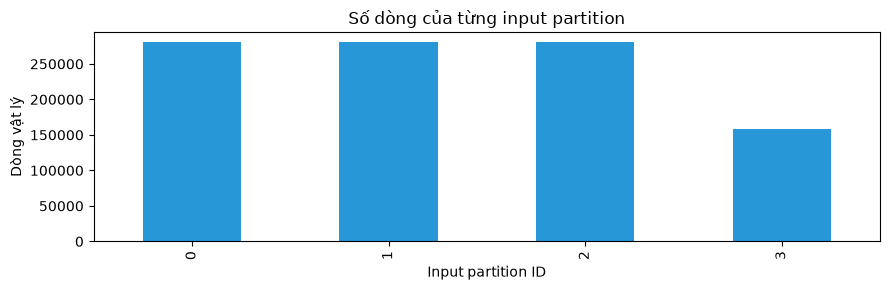

**Nhận xét:** Chiều cao cột biểu diễn số dòng, không phải số task đồng thời. Một dòng có thể chứa nhiều entry sau flatMap.

In [4]:
def input_stats(pid, iterator):
    from pyspark import TaskContext
    from helper import LOG_REGEX
    ctx = TaskContext.get()
    lines = entries = bad = ok = 0
    for line in iterator:
        lines += 1
        for entry in line.split(";"):
            entry = entry.strip()
            if not entry: continue
            entries += 1
            match = LOG_REGEX.match(entry)
            if not match: bad += 1
            elif int(match.group(2)) == 200: ok += 1
    yield dict(partition_id=pid, stage_id=ctx.stageId(), task_id=ctx.taskAttemptId(),
               physical_lines=lines, entries=entries, malformed=bad, http200=ok)
with phase("audit.input", "Đếm dòng vật lý và entry trong từng input partition"):
    input_rows = raw.mapPartitionsWithIndex(input_stats).collect()
input_table = pd.DataFrame(input_rows).sort_values("partition_id")
input_table["line_share_pct"] = input_table.physical_lines / max(1, input_table.physical_lines.sum()) * 100
table("Phân bổ dòng đầu vào", input_table)
assert len(input_table) == raw.getNumPartitions()
note(f"Tổng {input_table.physical_lines.sum():,} dòng và {input_table.entries.sum():,} entries. "
     f"Partition nhỏ nhất/lớn nhất: {input_table.physical_lines.min():,}/{input_table.physical_lines.max():,} dòng. "
     "Đây là chênh lệch khối lượng input; chưa đủ kết luận skew về thời gian thực thi.")
import matplotlib.pyplot as plt
ax = input_table.plot.bar(x="partition_id", y="physical_lines", legend=False, figsize=(9, 3), color="#2797d8")
ax.set(xlabel="Input partition ID", ylabel="Dòng vật lý", title="Số dòng của từng input partition")
plt.tight_layout()
plt.show()
note("Chiều cao cột biểu diễn số dòng, không phải số task đồng thời. Một dòng có thể chứa nhiều entry sau flatMap.")

## 5. Partition sau shuffle chứa gì?

Sau reduce, đơn vị là **key–count**, không còn là dòng vật lý. Một reduce partition nhận dữ liệu từ nhiều input partitions. Job audit bên dưới đo số key và tổng count đại diện; nó có thể tái sử dụng shuffle output, nhưng không giả định chắc chắn stage sẽ skipped.

In [5]:
def output_stats(pid, iterator):
    from pyspark import TaskContext
    ctx = TaskContext.get()
    keys = represented = 0
    for key, value in iterator:
        keys += 1
        represented += value
    yield dict(partition_id=pid, stage_id=ctx.stageId(), task_id=ctx.taskAttemptId(),
               key_records=keys, represented_entries=represented)
output_frames = []
for name, rdd in output_rdds.items():
    with phase("audit." + name, "Thống kê từng reduce partition của " + name):
        rows_out = rdd.mapPartitionsWithIndex(output_stats).collect()
    frame = pd.DataFrame(rows_out).assign(rdd=name)
    assert len(frame) == rdd.getNumPartitions()
    output_frames.append(frame)
output_table = pd.concat(output_frames, ignore_index=True)
table("Phân bổ bản ghi sau shuffle", output_table)
if MODE == "project":
    assert output_table.represented_entries.sum() == input_table.http200.sum()
else:
    assert dict(state_result).get("malformed", 0) == input_table.malformed.sum()
    assert sum(dict(state_result).values()) == input_table.entries.sum()
    assert http200 == input_table.http200.sum()
note("key_records là số key sau tổng hợp; represented_entries là tổng số entry mà các key đại diện. "
     "Không gán số dòng của Input P0 cho Reduce P0: shuffle đã thay đổi phân bố.")

**Phân bổ bản ghi sau shuffle**

,partition_id,stage_id,task_id,key_records,represented_entries,rdd
0,0,8,17,2,131077,country_counts
1,1,8,18,4,326908,country_counts
2,2,8,19,6,392044,country_counts
3,3,8,20,2,131003,country_counts


**Nhận xét:** key_records là số key sau tổng hợp; represented_entries là tổng số entry mà các key đại diện. Không gán số dòng của Input P0 cho Reduce P0: shuffle đã thay đổi phân bố.

## 6. Thu Job, Stage và mọi Task attempt từ Spark UI

Lấy dữ liệu từ đúng application hiện tại, đối chiếu với job group, đọc task theo trang. Nếu snapshot chưa đầy đủ notebook báo lỗi, không tự điền số minh họa. `planned_tasks` của stage skipped có thể khác 0, nhưng task **thực sự chạy** phải lấy từ task attempts. Không cộng số task khai báo ở mọi job vì có thể dùng chung dependency.

In [6]:
tracker = sc.statusTracker()
expected = {jid for gid in groups.values() for jid in tracker.getJobIdsForGroup(gid)}
deadline = time.monotonic() + 30
while True:
    jobs = [j for j in api("/jobs") if j["jobId"] in expected]
    stage_ids = {sid for j in jobs for sid in j.get("stageIds", [])}
    stages = [s for s in api("/stages") if s["stageId"] in stage_ids]
    complete = (len(jobs) == len(expected) and expected and
                all(j["status"] not in ("RUNNING", "UNKNOWN") for j in jobs) and
                stage_ids <= {s["stageId"] for s in stages} and
                all(s["status"] not in ("ACTIVE", "PENDING") for s in stages))
    if complete: break
    if time.monotonic() > deadline: raise RuntimeError("Spark REST snapshot chưa đầy đủ.")
    time.sleep(0.2)
scope = {jid: label for label, gid in groups.items() for jid in tracker.getJobIdsForGroup(gid)}
job_table = pd.DataFrame([dict(job_id=j["jobId"], scope=scope[j["jobId"]],
    action=explanations[scope[j["jobId"]]], status=j["status"], stage_ids=j["stageIds"],
    name=j.get("name")) for j in sorted(jobs, key=lambda j:j["jobId"])])
task_rows, stage_rows = [], []
for s in sorted(stages, key=lambda s:(s["stageId"], s["attemptId"])):
    sid, attempt = s["stageId"], s["attemptId"]
    detail = api(f"/stages/{sid}/{attempt}")
    batch_all, offset = [], 0
    while True:
        batch = api(f"/stages/{sid}/{attempt}/taskList?offset={offset}&length=1000")
        batch_all.extend(batch)
        if len(batch) < 1000: break
        offset += len(batch)
    assert len(batch_all) >= sum(detail.get(k, 0) for k in
        ("numCompleteTasks", "numFailedTasks", "numKilledTasks")), "Thiếu task attempts trong REST"
    read, write = detail.get("shuffleReadBytes", 0), detail.get("shuffleWriteBytes", 0)
    stage_rows.append(dict(stage_id=sid, stage_attempt=attempt,
        jobs=[j["jobId"] for j in jobs if sid in j["stageIds"]], status=s["status"],
        operation=s.get("name"), planned_tasks=s.get("numTasks"), actual_attempts=len(batch_all),
        shuffle_read_bytes=read, shuffle_write_bytes=write,
        input_bytes=detail.get("inputBytes"), call_site=detail.get("details")))
    for t in batch_all:
        m = t.get("taskMetrics") or {}
        sr, sw = m.get("shuffleReadMetrics") or {}, m.get("shuffleWriteMetrics") or {}
        task_rows.append(dict(stage_id=sid, stage_attempt=attempt, task_id=t["taskId"],
            partition_id=t.get("partitionId"), task_index=t.get("index"), attempt=t.get("attempt"),
            status=t.get("status"), executor=t.get("executorId"), host=t.get("host"),
            duration_ms=t.get("duration"), input_records=(m.get("inputMetrics") or {}).get("recordsRead"),
            shuffle_read_bytes=sr.get("localBytesRead", 0)+sr.get("remoteBytesRead", 0),
            shuffle_write_bytes=sw.get("bytesWritten", 0)))
stage_table = pd.DataFrame(stage_rows)
task_table = pd.DataFrame(task_rows)
assert not task_table.duplicated(["stage_id", "stage_attempt", "task_id"]).any()
assert set(groups) <= set(job_table.scope), "Thiếu job của một action"
table("Job ID → action → Stage IDs", job_table)
table("Stage ID → task attempts → shuffle", stage_table.drop(columns="call_site"))
table("Toàn bộ task attempts và partition được xử lý", task_table)
note("Job ID và Stage ID trong các bảng trên là số đo thật. Shuffle bytes cho biết vai trò đọc/ghi "
     "của stage; input_records là metric Spark, không thay thế số dòng vật lý đã tự đếm. "
     "Skipped nghĩa là dependency không chạy lại; không mặc định nguyên nhân là persist.")

**Job ID → action → Stage IDs**

,job_id,scope,action,status,stage_ids,name
0,0,main.schema,toDF: suy luận schema từ RDD country_counts,SUCCEEDED,"[0, 1]",runJob at PythonRDD.scala:218
1,1,main.take,country_df.take(10): tính và lấy Top 10,SUCCEEDED,"[2, 3]",take at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\2098156538.py:17
2,2,main.show,CLI country_df.show(10): action hiển thị riêng,SUCCEEDED,"[4, 5]",showString at NativeMethodAccessorImpl.java:0
3,3,audit.input,Đếm dòng vật lý và entry trong từng input partition,SUCCEEDED,[6],collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\3575562660.py:18
4,4,audit.country_counts,Thống kê từng reduce partition của country_counts,SUCCEEDED,"[7, 8]",collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\1483431175.py:13


**Stage ID → task attempts → shuffle**

,stage_id,stage_attempt,jobs,status,operation,planned_tasks,actual_attempts,shuffle_read_bytes,shuffle_write_bytes,input_bytes
0,0,0,[0],COMPLETE,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,4,4,0,1932,119902182
1,1,0,[0],COMPLETE,runJob at PythonRDD.scala:218,1,1,380,0,0
2,2,0,[1],SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,4,0,0,0,0
3,3,0,[1],COMPLETE,take at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\2098156538.py:17,4,4,1932,0,0
4,4,0,[2],SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,4,0,0,0,0
5,5,0,[2],COMPLETE,showString at NativeMethodAccessorImpl.java:0,4,4,1932,0,0
6,6,0,[3],COMPLETE,collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\3575562660.py:18,4,4,0,0,119902182
7,7,0,[4],SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,4,0,0,0,0
8,8,0,[4],COMPLETE,collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\1483431175.py:13,4,4,1932,0,0


**Toàn bộ task attempts và partition được xử lý**

,stage_id,stage_attempt,task_id,partition_id,task_index,attempt,status,executor,host,duration_ms,input_records,shuffle_read_bytes,shuffle_write_bytes
0,0,0,0,0,0,0,SUCCESS,driver,LAPTOP-LKF1QSU1,14036,280439,0,484
1,0,0,1,1,1,0,SUCCESS,driver,LAPTOP-LKF1QSU1,15194,280416,0,483
2,0,0,2,2,2,0,SUCCESS,driver,LAPTOP-LKF1QSU1,15735,280242,0,483
3,0,0,3,3,3,0,SUCCESS,driver,LAPTOP-LKF1QSU1,9187,158903,0,482
4,1,0,4,0,0,0,SUCCESS,driver,LAPTOP-LKF1QSU1,2162,0,380,0
5,3,0,5,0,0,0,SUCCESS,driver,LAPTOP-LKF1QSU1,5778,0,380,0
6,3,0,6,1,1,0,SUCCESS,driver,LAPTOP-LKF1QSU1,5944,0,553,0
7,3,0,7,2,2,0,SUCCESS,driver,LAPTOP-LKF1QSU1,5775,0,623,0
8,3,0,8,3,3,0,SUCCESS,driver,LAPTOP-LKF1QSU1,5768,0,376,0
9,5,0,9,0,0,0,SUCCESS,driver,LAPTOP-LKF1QSU1,4697,0,380,0


**Nhận xét:** Job ID và Stage ID trong các bảng trên là số đo thật. Shuffle bytes cho biết vai trò đọc/ghi của stage; input_records là metric Spark, không thay thế số dòng vật lý đã tự đếm. Skipped nghĩa là dependency không chạy lại; không mặc định nguyên nhân là persist.

## 7. Nối chính xác Partition → Task → Stage → Job

Chỉ nối số dòng với task audit đã trực tiếp đếm chúng. Bảng task nghiệp vụ vẫn thể hiện partition và input/shuffle metrics, không mượn số dòng của một task khác. Nếu phiên bản Spark không trả `partitionId`, dùng `task_index` để quan sát vị trí task, không tự sửa thành partition ID.

In [7]:
stage_to_jobs = {s: [j["jobId"] for j in jobs if s in j["stageIds"]] for s in stage_ids}
links = input_table.merge(task_table[["stage_id", "task_id", "stage_attempt", "status", "duration_ms", "executor"]],
    on=["stage_id", "task_id"], how="left", validate="one_to_one", indicator=True)
assert links["_merge"].eq("both").all()
links["job_ids"] = links.stage_id.map(stage_to_jobs)
table("Số dòng + task thực hiện phép đếm + stage + job", links.drop(columns="_merge"))
relations = []
for j in jobs:
    for sid in j["stageIds"]:
        for row in stage_rows:
            if row["stage_id"] != sid: continue
            relations.append(dict(job_id=j["jobId"], scope=scope[j["jobId"]],
                stage_id=sid, stage_attempt=row["stage_attempt"], status=row["status"],
                operation=row["operation"], tasks_observed=row["actual_attempts"],
                shuffle_read_bytes=row["shuffle_read_bytes"], shuffle_write_bytes=row["shuffle_write_bytes"]))
relations = pd.DataFrame(relations).sort_values(["job_id", "stage_id", "stage_attempt"])
table("Bảng dùng để thuyết trình Job / Stage / Task", relations)
note("Mỗi hàng là quan hệ một job với một stage attempt. Stage dùng chung có thể xuất hiện ở nhiều hàng; "
     "tổng task toàn application phải đếm duy nhất theo (stage_id, stage_attempt, task_id).")
for label in job_table.scope.unique():
    subset = job_table[job_table.scope == label]
    note(f"`{label}` kích hoạt Job {subset.job_id.tolist()}: {explanations[label]}.")

**Số dòng + task thực hiện phép đếm + stage + job**

,partition_id,stage_id,task_id,physical_lines,entries,malformed,http200,line_share_pct,stage_attempt,status,duration_ms,executor,job_ids
0,0,6,13,280439,290037,3992,274928,28.0439,0,SUCCESS,6778,driver,[3]
1,1,6,14,280416,289893,3824,275079,28.0416,0,SUCCESS,5797,driver,[3]
2,2,6,15,280242,290054,4007,274889,28.0242,0,SUCCESS,5789,driver,[3]
3,3,6,16,158903,164470,2097,156136,15.8903,0,SUCCESS,5793,driver,[3]


**Bảng dùng để thuyết trình Job / Stage / Task**

,job_id,scope,stage_id,stage_attempt,status,operation,tasks_observed,shuffle_read_bytes,shuffle_write_bytes
7,0,main.schema,0,0,COMPLETE,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,4,0,1932
8,0,main.schema,1,0,COMPLETE,runJob at PythonRDD.scala:218,1,380,0
5,1,main.take,2,0,SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,0,0,0
6,1,main.take,3,0,COMPLETE,take at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\2098156538.py:17,4,1932,0
3,2,main.show,4,0,SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,0,0,0
4,2,main.show,5,0,COMPLETE,showString at NativeMethodAccessorImpl.java:0,4,1932,0
2,3,audit.input,6,0,COMPLETE,collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\3575562660.py:18,4,0,0
0,4,audit.country_counts,7,0,SKIPPED,reduceByKey at D:\spark-core-apis\rdd_processing.py:43,0,0,0
1,4,audit.country_counts,8,0,COMPLETE,collect at C:\Users\admin\AppData\Local\Temp\ipykernel_24472\1483431175.py:13,4,1932,0


**Nhận xét:** Mỗi hàng là quan hệ một job với một stage attempt. Stage dùng chung có thể xuất hiện ở nhiều hàng; tổng task toàn application phải đếm duy nhất theo (stage_id, stage_attempt, task_id).

**Nhận xét:** `main.schema` kích hoạt Job [0]: toDF: suy luận schema từ RDD country_counts.

**Nhận xét:** `main.take` kích hoạt Job [1]: country_df.take(10): tính và lấy Top 10.

**Nhận xét:** `main.show` kích hoạt Job [2]: CLI country_df.show(10): action hiển thị riêng.

**Nhận xét:** `audit.input` kích hoạt Job [3]: Đếm dòng vật lý và entry trong từng input partition.

**Nhận xét:** `audit.country_counts` kích hoạt Job [4]: Thống kê từng reduce partition của country_counts.

## 8. Kết luận tự động và đối chiếu diagram

Diagram là mô hình giải thích, không phải bằng chứng của một lần chạy. Với `project`, schema inference và CLI display có thể phát sinh job riêng, không có semantic-count job như trong ảnh. Với `diagram`, hai phép reduce dùng hai key khác nhau nên không dùng chung shuffle; chỉ các partition của `rows` được dùng lại khi persist còn khả dụng. Không giả định chính xác ba job hoặc năm stage từ số action.

In [8]:
main_jobs = job_table[~job_table.scope.str.startswith("audit.")]
main_ids = {sid for ids in main_jobs.stage_ids for sid in ids}
main_stages = stage_table[stage_table.stage_id.isin(main_ids)]
main_tasks = task_table[task_table.stage_id.isin(main_ids)]
assert job_table.status.eq("SUCCEEDED").all(), "Có job thất bại"
assert digest(INPUT) == manifest.loc[manifest.file.eq("data/raw_logs.txt"), "sha256"].iloc[0]
note(f"Chế độ **{MODE}**, application `{sc.applicationId}`: input có **{raw.getNumPartitions()} partitions**, "
     f"**{input_table.physical_lines.sum():,} dòng**. Phần nghiệp vụ ghi nhận **{len(main_jobs)} jobs**, "
     f"**{len(main_stages)} stage attempts**, **{len(main_tasks)} task attempts**. "
     f"Phần audit có {len(job_table)-len(main_jobs)} jobs riêng.")
print("Stage status (nghiệp vụ):", main_stages.status.value_counts().to_dict())
print("Task status (nghiệp vụ):", main_tasks.status.value_counts().to_dict())
print("Executors:", sorted(task_table.executor.dropna().unique()))
note("Số task không đồng nghĩa số task chạy đồng thời. Local mode phân chia dữ liệu trên một máy; "
     "không mô phỏng network shuffle giữa các node hoặc phục hồi khi mất worker. "
     "Nếu đổi MODE/CACHE_DIAGRAM, restart kernel và chạy lại toàn bộ để so sánh công bằng về ID.")

**Nhận xét:** Chế độ **project**, application `local-1791483981441`: input có **4 partitions**, **1,000,000 dòng**. Phần nghiệp vụ ghi nhận **3 jobs**, **6 stage attempts**, **13 task attempts**. Phần audit có 2 jobs riêng.

Stage status (nghiệp vụ): {'COMPLETE': 4, 'SKIPPED': 2}
Task status (nghiệp vụ): {'SUCCESS': 13}
Executors: ['driver']


**Nhận xét:** Số task không đồng nghĩa số task chạy đồng thời. Local mode phân chia dữ liệu trên một máy; không mô phỏng network shuffle giữa các node hoặc phục hồi khi mất worker. Nếu đổi MODE/CACHE_DIAGRAM, restart kernel và chạy lại toàn bộ để so sánh công bằng về ID.

## 9. Kết thúc

Các bảng phía trên là snapshot của lần thực thi này. Spark UI chỉ còn xem trực tiếp trước khi chạy cell cuối. Sau khi chạy xong, **Save** notebook để giữ kết quả. Khi có lỗi giữa chừng, chạy cell này để dọn application rồi restart kernel trước khi thử lại.

In [9]:
if MODE == "diagram" and CACHE_DIAGRAM:
    rows.unpersist()
spark.stop()
print("Đã dừng Spark. Lưu notebook để giữ bảng phân tích.")

Đã dừng Spark. Lưu notebook để giữ bảng phân tích.
